# Writing Robot

Name: Anurak Narak
Student ID: 690631040

A KUKA iiwa arm holds a piece of chalk and writes on a vertical board.
Draw anything on the board with the drawing tool, and the robot writes it at the same place and size.
Everything is simulated in Drake (MIT 6.4210 Robotic Manipulation).

**How the system works**

```
Drawing: strokes of (u, v) points on the board
       ↓
trajectory of the chalk tip (PiecewisePose)
       ↓
  "position" mode: differential IK → iiwa in position mode
                           the tip is commanded PRESS mm into the board
  "force" mode   : hybrid force/position controller → iiwa in torque mode
                           the tip pushes on the board with a constant force F_DESIRED
       ↓  contact results
MeshcatWriter: draws the chalk line where the tip touches, and logs the normal force
```

**Course topics used in this notebook**

| Chapter | Topic | Section |
|---|---|---|
| 2 | `HardwareStation`, scenario YAML, iiwa control modes | 2, 8 |
| 3 | Spatial algebra (`RigidTransform`), pose trajectories (`PiecewisePose`), Jacobian, differential IK | 2, 6, 8 |
| 5 | Contact forces and friction | 1, 5, 9 |
| 6 | Inverse kinematics as an optimization problem | 3 |
| 8 | Hybrid force/position control, operational space control | 7 |

Credits: `MeshcatWriter` is adapted from `book/force/writing.ipynb`(Ex. in chp_8).
`PoseTrajectorySource` comes from `pick/exercises/08_robot_painter.ipynb`(from chp_3).

In [1]:
# import
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display
from pydrake.all import (
    AbstractValue,
    Capsule,
    ConstantVectorSource,
    Context,
    ContactResults,
    InverseKinematics,
    JacobianWrtVariable,
    DiagramBuilder,
    LeafSystem,
    PiecewisePose,
    RigidTransform,
    Rgba,
    Role,
    RotationMatrix,
    Simulator,
    Solve,
)

from manipulation.meshcat_utils import StartMeshcat
from manipulation.station import LoadScenario, MakeHardwareStation
from manipulation.systems import AddIiwaDifferentialIK

In [2]:
# shown meshcat
meshcat = StartMeshcat()

INFO:drake:Meshcat listening for connections at http://localhost:7000


## 1. Chalk and board models

This cell writes two SDF files.
- The chalk is a capsule. It is **welded** to the gripper, so it can never slip. (Grasping is not simulated.)
- The frame `tip` is at the end of the chalk. This is the point that is controlled.
- The board is a thin box welded to the world. Its frame `surface` is on the front face.
- Both objects have a friction coefficient μ = 0.3.

In [3]:
CHALK_RADIUS = 0.006  # m
CHALK_LENGTH = 0.08  # m (length of the cylinder part, without the round ends)
BOARD_SIZE = (0.5, 0.5, 0.02)  # m (width, height, thickness)

models_dir = Path("models").absolute()
models_dir.mkdir(exist_ok=True)

(models_dir / "chalk.sdf").write_text(f"""<?xml version="1.0"?>
<sdf version="1.7">
  <model name="chalk">
    <link name="chalk">
      <inertial>
        <mass>0.01</mass>
        <inertia><ixx>1e-5</ixx><iyy>1e-5</iyy><izz>1e-6</izz>
                 <ixy>0</ixy><ixz>0</ixz><iyz>0</iyz></inertia>
      </inertial>
      <visual name="visual">
        <geometry><capsule><radius>{CHALK_RADIUS}</radius><length>{CHALK_LENGTH}</length></capsule></geometry>
        <material><diffuse>0.95 0.95 0.9 1</diffuse></material>
      </visual>
      <collision name="collision">
        <geometry><capsule><radius>{CHALK_RADIUS}</radius><length>{CHALK_LENGTH}</length></capsule></geometry>
        <drake:proximity_properties>
          <drake:mu_dynamic>0.3</drake:mu_dynamic>
          <drake:mu_static>0.3</drake:mu_static>
        </drake:proximity_properties>
      </collision>
    </link>
    <frame name="tip">
      <pose relative_to="chalk">0 0 {CHALK_LENGTH / 2 + CHALK_RADIUS} 0 0 0</pose>
    </frame>
  </model>
</sdf>
""")

(models_dir / "board.sdf").write_text(f"""<?xml version="1.0"?>
<sdf version="1.7">
  <model name="board">
    <link name="board">
      <visual name="visual">
        <geometry><box><size>{BOARD_SIZE[0]} {BOARD_SIZE[1]} {BOARD_SIZE[2]}</size></box></geometry>
        <material><diffuse>0.08 0.25 0.15 1</diffuse></material>
      </visual>
      <collision name="collision">
        <geometry><box><size>{BOARD_SIZE[0]} {BOARD_SIZE[1]} {BOARD_SIZE[2]}</size></box></geometry>
        <drake:proximity_properties>
          <drake:mu_dynamic>0.3</drake:mu_dynamic>
          <drake:mu_static>0.3</drake:mu_static>
        </drake:proximity_properties>
      </collision>
    </link>
    <!-- frame on the front face of the board: x, y lie on the face, z points out of the face -->
    <frame name="surface">
      <pose relative_to="board">0 0 {BOARD_SIZE[2] / 2} 0 0 0</pose>
    </frame>
  </model>
</sdf>
""")

782

## 2. The scene and the board pose

**Pose notation.** `X_AB` is the pose of frame B, measured in frame A.
The four frames in this project:

| Frame | Meaning |
|---|---|
| W | world |
| B | board surface: u (x-axis) points right, v (y-axis) points up, n (z-axis) points out of the board, toward the robot |
| G | gripper body (`wsg::body`) |
| T | chalk tip (`chalk::tip`) |

Rules used: $X_{AC} = X_{AB}\,X_{BC}$, $\;X_{BA} = X_{AB}^{-1}$, $\;p^{A} = X_{AB}\,p^{B}$.

The four poses in the code:

| Code | Meaning | How to get it |
|---|---|---|
| `X_WB` | board surface in the world | chosen here |
| `X_GT` | chalk tip relative to the gripper (fixed, the chalk is welded) | `plant.CalcRelativeTransform(context, G, T)` |
| `X_WT` | chalk tip in the world (the planned pose) | `X_WB @ [u, v, h]` with a fixed rotation |
| `X_WG` | gripper in the world (what differential IK tracks) | $X_{WG} = X_{WT}\,X_{GT}^{-1}$ |

A point (u, v) on the board, at height h above the surface, is at $p_W = X_{WB}\,[u, v, h]^T$ in the world.

`BOARD_MODE` selects the board:
- `"vertical"`: a vertical board in front of the robot, like a whiteboard (default)
- `"horizontal"`: a board lying on a table

In both cases the drawing reads correctly when viewed from behind the robot
The gripper orientation follows the board automatically.

In [4]:
BOARD_MODE = "vertical"  # "vertical" or "horizontal"

if BOARD_MODE == "vertical":
    # m, centre of the board surface
    # Do not put the board too close: the iiwa elbow (joint 4) can only bend about 120°.
    # at x = 0.90 the joints stay farthest from their limits.
    BOARD_CENTER = [0.9, 0.0, 0.50]
    # The columns of this matrix are the board axes in world coordinates:
    # u = -y, v = +z, n = -x (the board faces the robot)
    R_WB = RotationMatrix(np.array([[0, 0, -1], [-1, 0, 0], [0, 1, 0]], float))
else:
    BOARD_CENTER = [0.55, 0.0, 0.10]
    # u = -y, v = +x, n = +z (facing up)
    R_WB = RotationMatrix.MakeZRotation(-np.pi / 2)

X_WB = RigidTransform(R_WB, BOARD_CENTER)


def rigid_transform_yaml(X):
    rpy = np.rad2deg(X.rotation().ToRollPitchYaw().vector())
    return (
        f"translation: [{X.translation()[0]:.6f}, {X.translation()[1]:.6f}, {X.translation()[2]:.6f}]\n"
        f"        rotation: !Rpy {{ deg: [{rpy[0]:.6f}, {rpy[1]:.6f}, {rpy[2]:.6f}] }}"
    )


Q_PAINTER = [0, 0.156, 0, -1.323, 0, 1.612, 0]  # downward-pointing pose from 08_robot_painter (chp_3)


def make_scenario(q_iiwa, control_mode="position_only", X_WB_actual=None):
    """Build the scenario YAML.
    - q_iiwa: initial joint angles of the arm (also the nominal posture for differential IK)
    - control_mode: "position_only" (send joint angles) or "torque_only" (send joint torques, for force control)
    - X_WB_actual: the REAL board pose. If None, it is the same as X_WB (what the robot believes).
      Use a different value in the experiment (Section 10) to simulate a board pose error."""
    if X_WB_actual is None:
        X_WB_actual = X_WB
    X_W_boardbody = X_WB_actual @ RigidTransform([0, 0, -BOARD_SIZE[2] / 2])
    joints = "\n".join(
        f"        iiwa_joint_{i + 1}: [{q:.6f}]" for i, q in enumerate(q_iiwa)
    )
    return f"""
directives:
- add_model:
    name: iiwa
    file: package://drake_models/iiwa_description/sdf/iiwa7_no_collision.sdf
    default_joint_positions:
{joints}
- add_weld:
    parent: world
    child: iiwa::iiwa_link_0
- add_model:
    name: wsg
    file: package://manipulation/hydro/schunk_wsg_50_with_tip.sdf
- add_weld:
    parent: iiwa::iiwa_link_7
    child: wsg::body
    X_PC:
        translation: [0, 0, 0.09]
        rotation: !Rpy {{ deg: [90, 0, 90] }}
- add_model:
    name: chalk
    file: file://{models_dir}/chalk.sdf
- add_weld:
    parent: wsg::body
    child: chalk::chalk
    X_PC:
        translation: [0, 0.11, 0]
        rotation: !Rpy {{ deg: [-90, 0, 0] }}
- add_model:
    name: board
    file: file://{models_dir}/board.sdf
- add_weld:
    parent: world
    child: board::board
    X_PC:
        {rigid_transform_yaml(X_W_boardbody)}
model_drivers:
    iiwa: !IiwaDriver
      control_mode: {control_mode}
      hand_model_name: wsg
    wsg: !SchunkWsgDriver {{}}
"""

## 3. Writing posture with IK (Chp_6)

Differential IK (Chp_3) is a *local* method: it moves the joints a little bit from the current posture.
If the robot starts far from a good writing posture (for example the "painter" pose that points down),
the arm can hit a joint limit while it turns toward the board.

Inverse kinematics is solved once, as an optimization problem, before the simulation:
- **Constraints (5):** the chalk tip is 3 cm in front of the board centre (3 constraints),
  and the chalk axis is perpendicular to the board (2 constraints).
  The rotation about the chalk axis is free.
- **Cost:** stay close to a comfortable posture `Q_COMFORT` (elbow up, arm in one vertical plane).
  The arm has 7 joints but only 5 numbers are fixed, so there are many solutions. The cost picks one.
- The problem is nonconvex, so several initial guesses are tried. The kept solution is the one closest to Q_COMFORT that is at least MIN_MARGIN away from every joint limit.

The result `q_write` is the start posture of the robot. Both controllers also use it as the reference posture for the extra (redundant) degree of freedom.

**Key equation (code names)**

$$\min_{q}\ \|q - q_{\text{COMFORT}}\|^2 \quad \text{subject to}\quad p_{WT}(q) = X_{WB}\,[0,\,0,\,h]^T, \qquad \angle\big(z_T(q),\,-n_W\big) \le 10^{-3}$$

(`p_WT`, `n_W`, `Q_COMFORT`, `hover = h = 0.03 m`; solver: SNOPT through `Solve(prog)`)

In [5]:
Q_COMFORT = np.array([0, 0.4, 0, -1.6, 0, 0, 0])
MIN_MARGIN = 0.3  # rad


def solve_writing_posture(X_WB, hover=0.03, num_guesses=20, seed=0):
    # Keep the station in a variable: the plant belongs to the station.
    # If the station is deleted, the plant becomes invalid and the kernel crashes.
    station = MakeHardwareStation(LoadScenario(data=make_scenario(Q_PAINTER)))
    plant = station.GetSubsystemByName("plant")
    T = plant.GetFrameByName("tip", plant.GetModelInstanceByName("chalk"))
    G = plant.GetFrameByName("body", plant.GetModelInstanceByName("wsg"))
    lo = plant.GetPositionLowerLimits()
    hi = plant.GetPositionUpperLimits()
    iiwa_idx = [plant.GetJointByName(f"iiwa_joint_{i + 1}").position_start() for i in range(7)]

    p_WT = X_WB @ np.array([0, 0, hover])
    n_W = X_WB.rotation().col(2)  # board normal in the world frame

    rng = np.random.default_rng(seed)
    solutions = []  # (distance to Q_COMFORT, joint-limit margin, q)
    for k in range(num_guesses):
        ik = InverseKinematics(plant)
        q = ik.q()
        ik.AddPositionConstraint(T, [0, 0, 0], plant.world_frame(), p_WT, p_WT)
        # the z-axis of the tip frame (the chalk axis) points into the board = direction -n
        ik.AddAngleBetweenVectorsConstraint(T, [0, 0, 1], plant.world_frame(), -n_W, 0, 1e-3)
        prog = ik.get_mutable_prog()
        q_guess = plant.GetPositions(plant.CreateDefaultContext())
        q_guess[iiwa_idx] = Q_COMFORT if k == 0 else rng.uniform(lo[iiwa_idx] * 0.8, hi[iiwa_idx] * 0.8)
        prog.SetInitialGuess(q, q_guess)
        prog.AddQuadraticErrorCost(np.eye(7), Q_COMFORT, q[iiwa_idx])
        result = Solve(prog)
        if not result.is_success():
            continue
        q_iiwa = result.GetSolution(q)[iiwa_idx]
        margin = np.min(np.minimum(q_iiwa - lo[iiwa_idx], hi[iiwa_idx] - q_iiwa))
        solutions.append((np.linalg.norm(q_iiwa - Q_COMFORT), margin, result.GetSolution(q)))
    if not solutions:
        raise RuntimeError("IK found no posture. The board may be too close or too far. Try another BOARD_CENTER.")

    good = [s for s in solutions if s[1] >= MIN_MARGIN]
    if good:
        _, margin, q_sol = min(good, key=lambda s: s[0])
    else:  # no posture is far enough from the limits: take the one with the largest margin
        _, margin, q_sol = max(solutions, key=lambda s: s[1])
    context = plant.CreateDefaultContext()
    plant.SetPositions(context, q_sol)
    R_WG = G.CalcPoseInWorld(context).rotation()
    return q_sol[iiwa_idx], R_WG, margin


q_write, R_WG_write, margin = solve_writing_posture(X_WB)
print("Writing posture from IK, q_write [rad]:", np.round(q_write, 3))
print(f"Smallest distance to a joint limit: {margin:.2f} rad")

Writing posture from IK, q_write [rad]: [-0.     0.502  0.    -1.565 -0.    -0.496  0.   ]
Smallest distance to a joint limit: 0.53 rad


## 4. The drawing (from the drawing tool)

The drawing tool shows the whole 50 × 50 cm board.
**The robot writes the drawing at the same position and size as in the drawing tool.**
The JSON contains (u, v) points in metres, with (0, 0) at the board centre — the same coordinates as in this notebook.

1. Open the drawing tool, draw anything, and press **Copy**.
2. Paste the text between `r'''` and `'''` below. Replace the example that is there now.
3. Run this cell. It shows the board with the strokes and the writing order.

**Everything after this cell (trajectory, evaluation and experiment) uses this drawing.**
After changing the drawing, run the cells below again.

- A **stroke** is one continuous line: mouse down → move → mouse up. A single click makes a dot.
- Curves are stored as many short straight segments. The tool removes extra points (RDP algorithm, max error 1 mm).

The example below is a test drawing: a house, a wave, a circle, a star and one dot.

Note: some strokes are closer than 2 cm to the board edge. The robot may miss a little there.
12 strokes, 112 points, drawing size 47.5 x 46.7 cm, total line length 131 cm


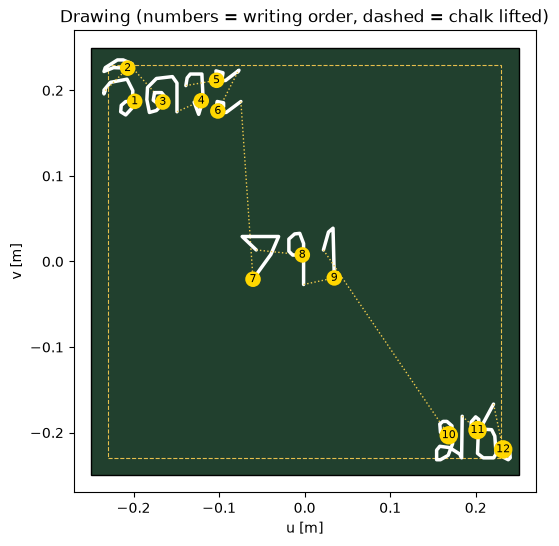

In [6]:
STROKES_JSON = r'''

{"format": "chalk-board/1", "unit": "m", "height_m": 1.0,
 "strokes": [
  [[-0.1986,0.1872],[-0.2091,0.1870],[-0.2143,0.1825],[-0.2150,0.1750],[-0.2091,0.1713],[-0.2016,0.1795],[-0.2008,0.1997],[-0.2076,0.2131],[-0.2270,0.2094],[-0.2345,0.2004],[-0.2345,0.1959],[-0.2330,0.1997]],
  [[-0.2068,0.2260],[-0.2233,0.2266],[-0.2345,0.2221],[-0.2330,0.2266],[-0.2188,0.2356],[-0.2121,0.2356],[-0.2016,0.2311],[-0.2001,0.2251]],
  [[-0.1657,0.1864],[-0.1739,0.1862],[-0.1769,0.1885],[-0.1754,0.1974],[-0.1672,0.1974],[-0.1635,0.1929],[-0.1635,0.1870],[-0.1732,0.1765],[-0.1814,0.1742],[-0.1844,0.1892],[-0.1836,0.2034],[-0.1732,0.2139],[-0.1545,0.2161],[-0.1492,0.2086],[-0.1492,0.1750]],
  [[-0.1208,0.1879],[-0.1291,0.1862],[-0.1238,0.1720],[-0.1186,0.1892],[-0.1201,0.2191],[-0.1336,0.2191],[-0.1373,0.2146],[-0.1388,0.2056]],
  [[-0.1029,0.2118],[-0.0962,0.2154],[-0.0954,0.2206],[-0.1036,0.2228],[-0.1029,0.2109],[-0.0924,0.2116],[-0.0767,0.2236],[-0.0782,0.2214]],
  [[-0.1014,0.1759],[-0.0947,0.1810],[-0.0947,0.1855],[-0.1022,0.1870],[-0.1044,0.1742],[-0.0917,0.1742],[-0.0745,0.1870]],
  [[-0.0603,-0.0207],[-0.0394,0.0083],[-0.0304,0.0292],[-0.0730,0.0292],[-0.0565,0.0135]],
  [[-0.0027,0.0077],[-0.0139,0.0075],[-0.0184,0.0120],[-0.0184,0.0262],[-0.0117,0.0322],[-0.0057,0.0329],[-0.0012,0.0210],[-0.0012,-0.0269]],
  [[0.0347,-0.0192],[0.0332,0.0389],[0.0279,0.0344],[0.0220,0.0135]],
  [[0.1685,-0.2031],[0.1633,-0.2033],[0.1588,-0.1996],[0.1580,-0.1899],[0.1618,-0.1869],[0.1663,-0.1869],[0.1722,-0.1921],[0.1730,-0.2130],[0.1678,-0.2265],[0.1588,-0.2317],[0.1543,-0.2317],[0.1543,-0.2205],[0.1580,-0.2160],[0.1693,-0.2175],[0.1812,-0.2250],[0.1835,-0.2295],[0.1842,-0.1809]],
  [[0.2021,-0.1971],[0.1947,-0.1973],[0.1947,-0.1876],[0.1999,-0.1816],[0.2036,-0.1846],[0.2021,-0.2243],[0.2089,-0.2295],[0.2208,-0.2295],[0.2238,-0.2250],[0.2223,-0.2041],[0.2186,-0.1966],[0.2051,-0.1958],[0.2208,-0.1667]],
  [[0.2321,-0.2196],[0.2351,-0.2168],[0.2395,-0.2183],[0.2403,-0.2295],[0.2380,-0.2317],[0.2321,-0.2287],[0.2328,-0.2183]]
]}

'''

HALF_BOARD = BOARD_SIZE[0] / 2  # 0.25 m
EDGE_MARGIN = 0.02  # m: warn if a stroke is closer than this to the board edge


def load_strokes_json(text):
    """Convert the JSON from the drawing tool into a list of strokes.
    Each stroke is an (N, 2) array of (u, v) points in metres on the board."""
    try:
        data = json.loads(text)
    except json.JSONDecodeError as e:
        raise ValueError("Cannot read the JSON. Copy it again from the tool and paste everything from { to }.") from e
    if data.get("format") != "chalk-board/1":
        raise ValueError('This JSON is not from the current drawing tool (format must be "chalk-board/1").')

    strokes = []
    for s in data["strokes"]:
        s = np.array(s, float).reshape(-1, 2)
        if len(s) == 0:
            continue
        if len(s) == 1:  # a dot: touch the board and lift at the same place
            s = np.vstack([s, s])
        strokes.append(s)
    if not strokes:
        raise ValueError("The JSON has no strokes.")
    pts = np.vstack(strokes)
    if np.any(np.abs(pts) > HALF_BOARD):
        raise ValueError("Some points are outside the board (|u| or |v| is more than 25 cm).")
    if np.any(np.abs(pts) > HALF_BOARD - EDGE_MARGIN):
        print("Note: some strokes are closer than 2 cm to the board edge. The robot may miss a little there.")
    return strokes


def stroke_length(s):
    return float(np.sum(np.linalg.norm(np.diff(s, axis=0), axis=1)))


def draw_board(ax, title=""):
    """Draw the 50 x 50 cm board (dark green) with a dashed line for the 2 cm edge margin."""
    ax.add_patch(plt.Rectangle((-HALF_BOARD, -HALF_BOARD), 2 * HALF_BOARD, 2 * HALF_BOARD,
                               fc=(0.13, 0.25, 0.18), ec="k"))
    m = HALF_BOARD - EDGE_MARGIN
    ax.add_patch(plt.Rectangle((-m, -m), 2 * m, 2 * m, fc="none", ec=(0.9, 0.75, 0.3), ls="--", lw=0.8))
    ax.set_xlim(-0.27, 0.27)
    ax.set_ylim(-0.27, 0.27)
    ax.set_aspect("equal")
    ax.set_xlabel("u [m]")
    ax.set_ylabel("v [m]")
    ax.set_title(title)


strokes = load_strokes_json(STROKES_JSON)

all_pts = np.vstack(strokes)
w_cm, h_cm = (all_pts.max(axis=0) - all_pts.min(axis=0)) * 100
total_length = sum(stroke_length(s) for s in strokes)
print(f"{len(strokes)} strokes, {len(all_pts)} points, drawing size {w_cm:.1f} x {h_cm:.1f} cm, "
      f"total line length {total_length * 100:.0f} cm")

fig, ax = plt.subplots(figsize=(6, 6))
draw_board(ax, "Drawing (numbers = writing order, dashed = chalk lifted)")
for i, s in enumerate(strokes):
    if i > 0:  # travel with the chalk lifted, from the end of the last stroke to this one
        a, b = strokes[i - 1][-1], s[0]
        ax.plot([a[0], b[0]], [a[1], b[1]], ":", color=(0.95, 0.8, 0.3), lw=1)
    ax.plot(s[:, 0], s[:, 1], "-", lw=2.5, color="white", solid_capstyle="round")
    ax.annotate(str(i + 1), s[0], fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="gold", ec="none"))
plt.show()

## 5. Two small Drake systems

**`MeshcatWriter`** reads the contact results every 10 ms. When the chalk touches the board it draws a short white line in Meshcat.
It is adapted from `book/force/writing.ipynb` with three changes:
1. The original code checked the swapped contact pair with `id_B` twice. This version uses id_A / id_B.
2. It saves every contact point in `self.drawn_points`, so the accuracy can be measured later.
3. It saves the normal force (the force perpendicular to the board) in `self.normal_forces`.

Normal force from the contact force (Ch. 5): $f_n = |F_{\text{contact}} \cdot n_W|$

**`PoseTrajectorySource`** outputs the pose of a `PiecewisePose` trajectory at the current simulation time.
Differential IK reads this pose as its target.

In [7]:
class MeshcatWriter(LeafSystem):
    def __init__(
        self,
        meshcat,
        drawing_geometry_ids,
        canvas_geometry_ids,
        rgba,
        board_normal_W,
        line_width=0.004,
        draw_threshold=0.002,
        draw=True,
    ):
        LeafSystem.__init__(self)
        self._meshcat = meshcat
        self._drawing_geometry_ids = set(drawing_geometry_ids)
        self._canvas_geometry_ids = set(canvas_geometry_ids)
        self._rgba = rgba
        self._n_W = np.asarray(board_normal_W)
        self._line_width = line_width  # only for the picture in Meshcat, not used in the evaluation
        self._draw_threshold = draw_threshold
        self._draw = draw
        self.drawn_points = []  # (time, contact point in world frame) every time the chalk touches the board
        self.normal_forces = []  # (time, normal force [N])

        self.DeclareAbstractInputPort(
            "contact_results", AbstractValue.Make(ContactResults())
        )
        self.DeclarePeriodicDiscreteUpdateEvent(0.01, 0, self.MaybeDraw)
        self._p_WLastDraw_index = self.DeclareDiscreteState(3)
        self._was_in_contact_index = self.DeclareDiscreteState([0])
        self._num_drawn_index = self.DeclareDiscreteState([0])

    def _find_contact(self, results):
        """Return (contact point, normal force), or (None, 0) if the chalk does not touch the board."""
        draw, canvas = self._drawing_geometry_ids, self._canvas_geometry_ids
        for i in range(results.num_point_pair_contacts()):
            info = results.point_pair_contact_info(i)
            pair = info.point_pair()
            f_n = abs(np.dot(info.contact_force(), self._n_W))
            if pair.id_A in draw and pair.id_B in canvas:
                return pair.p_WCb, f_n
            if pair.id_B in draw and pair.id_A in canvas:
                return pair.p_WCa, f_n
        for i in range(results.num_hydroelastic_contacts()):
            info = results.hydroelastic_contact_info(i)
            surface = info.contact_surface()
            ids = {surface.id_M(), surface.id_N()}
            if ids & draw and ids & canvas:
                f_n = abs(np.dot(info.F_Ac_W().translational(), self._n_W))
                return surface.centroid(), f_n
        return None, 0.0

    def MaybeDraw(self, context, discrete_state):
        p_WDraw, f_n = self._find_contact(self.get_input_port().Eval(context))
        self.normal_forces.append((context.get_time(), f_n))
        if p_WDraw is None:
            discrete_state.set_value(self._was_in_contact_index, [0])
            return

        self.drawn_points.append((context.get_time(), np.array(p_WDraw)))
        p_WLastDraw = context.get_discrete_state(self._p_WLastDraw_index).get_value()
        was_in_contact = context.get_discrete_state(self._was_in_contact_index)[0]
        num_drawn = int(context.get_discrete_state(self._num_drawn_index)[0])

        length = np.linalg.norm(p_WDraw - p_WLastDraw)
        if was_in_contact and length > self._draw_threshold:
            if self._draw:
                path = f"writer/{num_drawn}"
                self._meshcat.SetObject(path, Capsule(self._line_width, length), self._rgba)
                self._meshcat.SetTransform(
                    path,
                    RigidTransform(
                        RotationMatrix.MakeFromOneVector(p_WDraw - p_WLastDraw, 2),
                        (p_WDraw + p_WLastDraw) / 2,
                    ),
                )
            discrete_state.set_value(self._num_drawn_index, [num_drawn + 1])
            discrete_state.set_value(self._p_WLastDraw_index, p_WDraw)
        elif not was_in_contact:
            discrete_state.set_value(self._p_WLastDraw_index, p_WDraw)
        discrete_state.set_value(self._was_in_contact_index, [1])


class PoseTrajectorySource(LeafSystem):
    """Outputs the pose of a PiecewisePose at the current time (from 08_robot_painter.ipynb)."""

    def __init__(self, pose_trajectory: PiecewisePose):
        LeafSystem.__init__(self)
        self._traj = pose_trajectory
        self.DeclareAbstractOutputPort(
            "pose", lambda: AbstractValue.Make(RigidTransform()), self.CalcPose
        )

    def CalcPose(self, context: Context, output: AbstractValue):
        output.set_value(self._traj.GetPose(context.get_time()))

## 6. From strokes to a trajectory (Ch. 3)

Each stroke becomes six moves of the chalk tip. h is the height of the tip above the board surface.

| Move | What the tip does | Height h | Speed |
|---|---|---|---|
| 1 | Travel to above the start of the stroke | `LIFT` = 30 mm | `TRAVEL_SPEED` = 10 cm/s |
| 2 | Move down close to the board | 30 → 5 mm (`APPROACH`) | `TRAVEL_SPEED / 3` ≈ 3.3 cm/s |
| 3 | Touch the board | 5 → −2 mm (`-PRESS`) | ≈ 3.3 cm/s |
| 4 | Wait, so the chalk stops bouncing | −2 mm | `DWELL` = 0.6 s |
| 5 | Draw through all points of the stroke | −2 mm | `WRITE_SPEED` = 3 cm/s |
| 6 | Lift the chalk | −2 → 30 mm | ≈ 3.3 cm/s |

After the last stroke the tip goes back to above the board centre.
In force mode, move 3 is different: the controller ignores h = −2 mm and pushes with `F_DESIRED` instead (Section 7).
The switch to force control happens by time, at `t_down`, when the plan reaches 5 mm.

**Key equations (code names)**

- Tip pose from board coordinates (`tip_pose(uv, h)`): $\;X_{WT} = \big(R_{WT},\; X_{WB}\,[u,\,v,\,h]^T\big)$, with a constant rotation `R_WT`
- Time of the next keyframe (`go(X_WT, speed, min_dt)`): $\;t_{k+1} = t_k + \max\!\big(\|p_{k+1} - p_k\| / \text{speed},\ \Delta t_{\min}\big)$
- Between two keyframes, `PiecewisePose.MakeLinear` interpolates at constant speed:
  $\;p(t) = p_k + \dfrac{t - t_k}{t_{k+1} - t_k}\,(p_{k+1} - p_k)$
- Gripper trajectory for differential IK (`traj_G`): $\;X_{WG}(t) = X_{WT}(t)\,X_{GT}^{-1}$
- `pen_down_windows`: time windows when force control pushes (from `t_down` to the end of the stroke)
- `writing_windows`: time windows when the chalk is dragged (used to measure the force)

Keyframes: 162, total time: 88.3 s, drawing time (chalk dragged): 43.7 s
X_GT (tip in gripper frame): translation [-0.     0.156 -0.   ] m


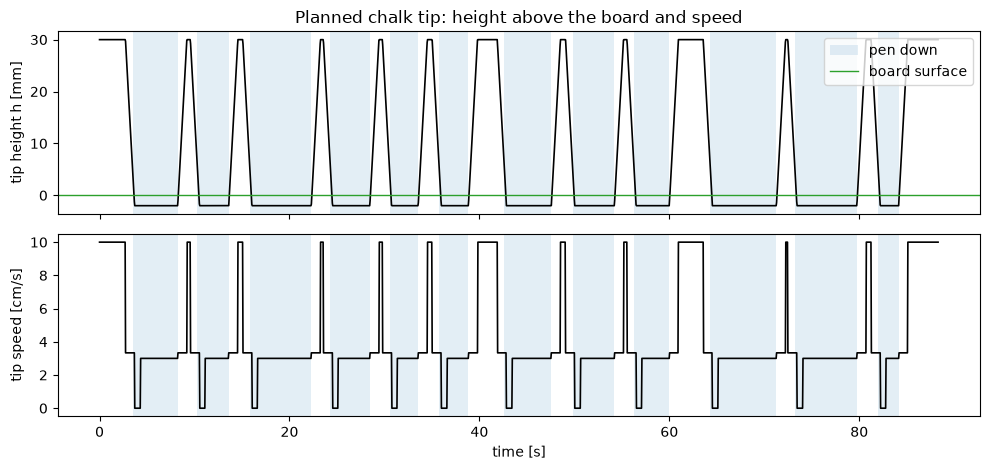

In [8]:
WRITE_SPEED = 0.03  # m/s while writing
TRAVEL_SPEED = 0.10  # m/s while moving with the chalk lifted
LIFT = 0.03  # m, height of the tip when the chalk is lifted
APPROACH = 0.005  # m, the tip comes down to this height in position control; then "pen down" starts
PRESS = 0.002  # m, how deep the tip is commanded into the board (position mode)
DWELL = 0.6  # s, wait after touching, so the contact settles before drawing

# Gripper orientation while writing: from the IK posture in Section 3 (the chalk is perpendicular to the board).
# R_BG is the gripper rotation relative to the board. It is constant during writing.
R_BG = X_WB.rotation().inverse() @ R_WG_write


def make_writing_trajectory(strokes, X_WG_start, X_GT, t_start=2.0):
    """Return (gripper trajectory, tip trajectory, pen_down_windows, writing_windows).
    - pen_down_windows: when the force controller controls the force (from pressing down until just before lifting)
    - writing_windows: when the chalk is being dragged (after DWELL); used to measure the force while writing"""
    R_WG = X_WB.rotation() @ R_BG
    R_WT = R_WG @ X_GT.rotation()

    def tip_pose(uv, h):
        return RigidTransform(R_WT, X_WB @ np.array([uv[0], uv[1], h]))

    tip_poses, times = [X_WG_start @ X_GT], [0.0]
    pen_down_windows, writing_windows = [], []

    def go(X_WT, speed, min_dt=0.2):
        dist = np.linalg.norm(X_WT.translation() - tip_poses[-1].translation())
        times.append(times[-1] + max(dist / speed, min_dt))
        tip_poses.append(X_WT)

    first = True
    for s in strokes:
        if first:  # move 1 (first stroke): at least t_start seconds, so the simulation can settle
            go(tip_pose(s[0], LIFT), TRAVEL_SPEED, min_dt=t_start)
            first = False
        else:  # move 1
            go(tip_pose(s[0], LIFT), TRAVEL_SPEED)
        go(tip_pose(s[0], APPROACH), TRAVEL_SPEED / 3)  # move 2
        t_down = times[-1]
        go(tip_pose(s[0], -PRESS), TRAVEL_SPEED / 3)  # move 3
        go(tip_pose(s[0], -PRESS), 1.0, min_dt=DWELL)  # move 4: same point, so the time is DWELL
        t_write = times[-1]
        for uv in s[1:]:  # move 5
            go(tip_pose(uv, -PRESS), WRITE_SPEED, min_dt=0.05)
        pen_down_windows.append((t_down, times[-1]))
        writing_windows.append((t_write, times[-1]))
        go(tip_pose(s[-1], LIFT), TRAVEL_SPEED / 3)  # move 6
    go(X_WG_start @ X_GT, TRAVEL_SPEED)  # back to above the board centre

    traj_T = PiecewisePose.MakeLinear(times, tip_poses)
    traj_G = PiecewisePose.MakeLinear(times, [X @ X_GT.inverse() for X in tip_poses])
    return traj_G, traj_T, pen_down_windows, writing_windows


def start_pose_and_X_GT(q_iiwa):
    """Gripper pose at the start posture, and the fixed pose of the tip relative to the gripper."""
    station = MakeHardwareStation(LoadScenario(data=make_scenario(q_iiwa)))
    plant = station.GetSubsystemByName("plant")
    context = plant.CreateDefaultContext()
    G = plant.GetFrameByName("body", plant.GetModelInstanceByName("wsg"))
    T = plant.GetFrameByName("tip", plant.GetModelInstanceByName("chalk"))
    return G.CalcPoseInWorld(context), plant.CalcRelativeTransform(context, G, T)


# Preview: the planned trajectory, before any simulation
X_WG_start, X_GT = start_pose_and_X_GT(q_write)
traj_G, traj_T, pen_down_windows, writing_windows = make_writing_trajectory(strokes, X_WG_start, X_GT)

T_end = traj_T.end_time()
t_writing = sum(t1 - t0 for t0, t1 in writing_windows)
print(f"Keyframes: {len(traj_T.get_segment_times())}, total time: {T_end:.1f} s, "
      f"drawing time (chalk dragged): {t_writing:.1f} s")
print(f"X_GT (tip in gripper frame): translation {np.round(X_GT.translation(), 3)} m")

ts = np.linspace(0, T_end, 2000)
X_BW = X_WB.inverse()
h_mm = np.array([(X_BW @ traj_T.GetPose(t).translation())[2] for t in ts]) * 1000
speed_cm = np.array([np.linalg.norm(traj_T.GetVelocity(t).ravel()[3:]) for t in ts]) * 100

fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
for ax in axes:
    for k, (t0, t1) in enumerate(pen_down_windows):
        ax.axvspan(t0, t1, color="tab:blue", alpha=0.12, lw=0, label="pen down" if k == 0 else None)
axes[0].plot(ts, h_mm, color="k", lw=1.2)
axes[0].axhline(0, color="tab:green", lw=1, label="board surface")
axes[0].set_ylabel("tip height h [mm]")
axes[0].legend(loc="upper right")
axes[0].set_title("Planned chalk tip: height above the board and speed")
axes[1].plot(ts, speed_cm, color="k", lw=1.2)
axes[1].set_ylabel("tip speed [cm/s]")
axes[1].set_xlabel("time [s]")
plt.tight_layout()
plt.show()

## 7. Hybrid force/position controller (Ch. 8)

**Problem with position control.** The tip is commanded 2 mm into the board.
The resulting force depends on how well the robot knows the board position.
If the board is 2–3 mm farther than expected, the chalk does not touch at all.
If it is closer, the robot pushes much too hard. (Ch. 8 discusses the same problem in "peg in hole".)

**The idea of Ch. 8: split the directions (hybrid force/position control).**
- Directions **parallel to the board** and the **rotation**: control the position with a virtual spring and damper (Cartesian stiffness).
- Direction **normal to the board**: control the force. Push with a constant force `F_DESIRED`, wherever the board is.

The controller is written in the operational space control form (Ch. 8, "Cartesian stiffness and operational space control").
It is a direct formula, computed every 1 ms. There is no optimization.

**Key equations (code names)**

1. Virtual spring and damper (desired acceleration of the tip):
   $$a_{\text{rot}} = K_r\, e_R + D_r(\omega_d - \omega), \qquad a_{\text{lin}} = K_p\,(p_d - p) + K_d\,(v_d - v)$$
   `e_R` = axis·angle of $R_d R^T$; `p_d`, `v_d`, `R_d`, `ω_d` come from `traj_T` at time t.
2. Pen down: remove the normal direction with the projection `P_t`:
   $$a_{\text{lin}} \leftarrow P_t\, a_{\text{lin}}, \qquad P_t = I - n\,n^T$$
3. Operational space inertia `Lambda` (the arm mass "felt" at the tip) turns acceleration into force:
   $$F = \Lambda \begin{bmatrix} a_{\text{rot}} \\ a_{\text{lin}} \end{bmatrix}, \qquad \Lambda = (J\,M^{-1}J^T)^{-1}$$
4. Pen down: add the constant normal force and a damper in the normal direction (`s` ramps from 0 to 1 in `FORCE_RAMP` seconds):
   $$F_{\text{lin}} \leftarrow F_{\text{lin}} - s\,F_{\text{DESIRED}}\,n - D_n\,(n^T v)\,n$$
5. Joint torques, plus a posture term in the null space (pulls the joints toward `q_write` without moving the tip):
   $$\tau = J^T F + N\,M\,\big(K_q(q_0 - q) - D_q\,\dot q\big), \qquad N = I - J^T \bar J^T, \quad \bar J^T = \Lambda\,J\,M^{-1}$$
   Then `tau` is clipped to the joint torque limits.

- `J` = Jacobian of the chalk tip (6×7, Ch. 3), `M` = mass matrix of the arm.
- Multiplying by Λ makes the directions really independent. With only `Jᵀ f` (no Λ),
  a force along the board also pushes the chalk away from the board. As a result, the chalk bounces from time to time.
- The iiwa has 7 joints but the task uses 6 dimensions, so 1 direction is free (redundant).
  The posture term uses it to stay near `q_0` (= `q_write`). `N` is "dynamically consistent": it never accelerates the tip.
- No gravity compensation is added here: in `torque_only` mode the Drake iiwa driver already does it
  (the course notebook `04_peg_in_hole` says the same).
- When pen down starts, the force grows from 0 over `FORCE_RAMP` seconds. Before contact the chalk moves toward the board at about `F_DESIRED / D_n`.

In [9]:
F_DESIRED = 3.0  # N, desired pushing force of the chalk
FORCE_RAMP = 0.3  # s

GAINS = dict(
    K_p=1000.0,  # 1/s²   stiffness along the board (acceleration units, because it is multiplied by Λ later)
    K_d=63.0,  # 1/s     ≈ 2√K_p (critical damping)
    D_n=200.0,  # N·s/m  damping in the normal direction during force control (the chalk moves in at ≈ F/D_n = 1.5 cm/s)
    K_r=1000.0,  # 1/s²   rotational stiffness
    D_r=63.0,  # 1/s
    K_q=25.0,  # 1/s²   null-space posture stiffness
    D_q=10.0,  # 1/s
)


class HybridForcePositionController(LeafSystem):
    def __init__(self, plant, traj_T, pen_down_windows, n_W, q_nominal, gains, f_desired):
        LeafSystem.__init__(self)
        self._plant = plant
        self._context = plant.CreateDefaultContext()  # a separate context for kinematics
        self._iiwa = plant.GetModelInstanceByName("iiwa")
        self._T = plant.GetFrameByName("tip", plant.GetModelInstanceByName("chalk"))
        self._W = plant.world_frame()
        self._v_idx = [
            plant.GetJointByName(f"iiwa_joint_{i + 1}").velocity_start() for i in range(7)
        ]
        self._traj = traj_T
        self._windows = pen_down_windows
        self._n = np.asarray(n_W).reshape(3)
        self._P_t = np.eye(3) - np.outer(self._n, self._n)
        self._q0 = np.asarray(q_nominal)
        self._g = gains
        self._f_d = f_desired
        self._tau_max = np.array(
            [plant.get_joint_actuator(i).effort_limit() for i in plant.GetJointActuatorIndices(self._iiwa)]
        )

        self.DeclareVectorInputPort("iiwa_state", 14)
        self.DeclareVectorOutputPort("iiwa_torque", 7, self.CalcTorque)

    def pen_down_scale(self, t):
        """0 = position control in all directions, 1 = full force control in the normal direction."""
        for t0, t1 in self._windows:
            if t0 <= t < t1:
                return min((t - t0) / FORCE_RAMP, 1.0)
        return 0.0

    def CalcTorque(self, context, output):
        t = context.get_time()
        x = self.get_input_port().Eval(context)
        q, v = x[:7], x[7:]  # measured joint angles and velocities
        self._plant.SetPositions(self._context, self._iiwa, q)
        self._plant.SetVelocities(self._context, self._iiwa, v)

        X_WT = self._T.CalcPoseInWorld(self._context)
        J = self._plant.CalcJacobianSpatialVelocity(
            self._context, JacobianWrtVariable.kV, self._T, [0, 0, 0], self._W, self._W
        )[:, self._v_idx]
        V = J @ v
        w, vel = V[:3], V[3:]

        X_d = self._traj.GetPose(t)
        V_d = self._traj.GetVelocity(t).ravel()
        g = self._g

        # step 1: desired acceleration of the tip (rotation + translation)
        aa = (X_d.rotation() @ X_WT.rotation().inverse()).ToAngleAxis()
        a_rot = g["K_r"] * aa.axis() * aa.angle() + g["D_r"] * (V_d[:3] - w)
        a_lin = g["K_p"] * (X_d.translation() - X_WT.translation()) + g["K_d"] * (V_d[3:] - vel)
        s = self.pen_down_scale(t)
        if s > 0:
            a_lin = self._P_t @ a_lin  # step 2: no position control in the normal direction

        # step 3: operational space inertia, Λ = (J M⁻¹ Jᵀ)⁻¹
        M = self._plant.CalcMassMatrix(self._context)[np.ix_(self._v_idx, self._v_idx)]
        Minv = np.linalg.inv(M)
        Lambda = np.linalg.inv(J @ Minv @ J.T)
        F = Lambda @ np.concatenate([a_rot, a_lin])
        if s > 0:
            n = self._n
            # Note: Λ a also has a small normal part (Λ is not diagonal). It is kept on purpose,
            # so that motion along the board does not push the chalk away. (Without it, the chalk bounces.)
            # The cost: the real force varies about ±1 N around F_DESIRED. See the experiment in Section 10.
            F[3:] += -s * self._f_d * n - g["D_n"] * np.dot(n, vel) * n  # step 4
        tau = J.T @ F  # step 5

        # step 5: null-space posture control (dynamically consistent)
        Jbar_T = Lambda @ J @ Minv
        N = np.eye(7) - J.T @ Jbar_T
        tau += N @ (M @ (g["K_q"] * (self._q0 - q) - g["D_q"] * v))

        output.SetFromVector(np.clip(tau, -self._tau_max, self._tau_max))

## 8. Build the system and run the simulation

`build_and_run` connects all Drake systems in a `DiagramBuilder`, then runs the `Simulator`.
The plant uses a time step of 1 ms, so a 90 s drawing is about 90,000 simulation steps.

- `control="position"` (Ch. 3): `PoseTrajectorySource(traj_G)` → differential IK → `iiwa.position`.
  Differential IK solves a small QP every step (Drake `DifferentialInverseKinematicsIntegrator`):
  $$\min_{\dot q,\,\alpha}\ -100\,\alpha + \big\|P\,(\dot q - K(q_{\text{write}} - q))\big\|^2 \quad \text{s.t.}\quad J\dot q = \alpha V,\ \ 0 \le \alpha \le 1,\ \ |\dot q_i| \le \dot q_{i,\max}$$
  Then the iiwa driver tracks the joint angles with a stiff PID controller.
- `control="force"` (Ch. 8): measured state `iiwa.state_estimated` → `HybridForcePositionController(traj_T)` → `iiwa.torque`.
- `board_offset` is used in the experiment (Section 10): how much farther the REAL board is than the board the robot believes in (negative = closer).

In [10]:
def build_and_run(strokes, control="position", board_offset=0.0, realtime_rate=0.0, record=True):
    meshcat.Delete()
    builder = DiagramBuilder()
    X_WB_actual = X_WB @ RigidTransform([0, 0, -board_offset])
    mode = {"position": "position_only", "force": "torque_only"}[control]
    scenario = LoadScenario(data=make_scenario(q_write, mode, X_WB_actual))
    station = builder.AddSystem(MakeHardwareStation(scenario, meshcat=meshcat))
    plant = station.GetSubsystemByName("plant")
    scene_graph = station.GetSubsystemByName("scene_graph")

    # start pose of the gripper, and the fixed transform from the gripper to the chalk tip
    temp_context = plant.CreateDefaultContext()
    G = plant.GetFrameByName("body", plant.GetModelInstanceByName("wsg"))
    T = plant.GetFrameByName("tip", plant.GetModelInstanceByName("chalk"))
    X_WG_start = G.CalcPoseInWorld(temp_context)
    X_GT = plant.CalcRelativeTransform(temp_context, G, T)

    traj, traj_T, pen_down_windows, writing_windows = make_writing_trajectory(
        strokes, X_WG_start, X_GT
    )

    if control == "position":
        # trajectory → differential IK → iiwa (position control)
        traj_source = builder.AddSystem(PoseTrajectorySource(traj))
        controller_plant = station.GetSubsystemByName(
            "iiwa_controller_plant_pointer_system"
        ).get()
        diff_ik = AddIiwaDifferentialIK(
            builder, controller_plant, frame=controller_plant.GetFrameByName("body")
        )
        builder.Connect(traj_source.get_output_port(), diff_ik.GetInputPort("X_AE_desired"))
        builder.Connect(
            station.GetOutputPort("iiwa.state_estimated"),
            diff_ik.GetInputPort("robot_state"),
        )
        builder.Connect(diff_ik.get_output_port(), station.GetInputPort("iiwa.position"))
    else:
        # chalk tip trajectory → hybrid force/position controller → iiwa (torque control)
        # Note: the controller gets X_WB (where the robot BELIEVES the board is), not X_WB_actual. The robot does not know the real pose.
        controller = builder.AddSystem(
            HybridForcePositionController(
                plant, traj_T, pen_down_windows, X_WB.rotation().col(2),
                q_write, GAINS, F_DESIRED,
            )
        )
        builder.Connect(station.GetOutputPort("iiwa.state_estimated"), controller.get_input_port())
        builder.Connect(controller.get_output_port(), station.GetInputPort("iiwa.torque"))

    # close the gripper fingers near the chalk (only for the look; the chalk is already welded)
    wsg_cmd = builder.AddSystem(ConstantVectorSource([0.03]))
    builder.Connect(wsg_cmd.get_output_port(), station.GetInputPort("wsg.position"))

    # writer
    inspector = scene_graph.model_inspector()
    chalk_ids = inspector.GetGeometries(
        plant.GetBodyFrameIdOrThrow(plant.GetBodyByName("chalk").index()),
        Role.kProximity,
    )
    board_ids = inspector.GetGeometries(
        plant.GetBodyFrameIdOrThrow(plant.GetBodyByName("board").index()),
        Role.kProximity,
    )
    writer = builder.AddSystem(
        MeshcatWriter(
            meshcat, chalk_ids, board_ids, Rgba(1, 1, 1, 1), X_WB.rotation().col(2), draw=record
        )
    )
    builder.Connect(station.GetOutputPort("contact_results"), writer.get_input_port())

    diagram = builder.Build()
    diagram.set_name(f"writing_robot_{control}")

    # draw the target strokes as thin yellow lines, 1 mm in front of the board, for comparison
    for i, s in enumerate(strokes):
        pts = np.array([X_WB_actual @ np.array([u, v, 0.001]) for u, v in s]).T
        meshcat.SetLine(f"target/{i}", pts, 1.0, Rgba(1, 0.8, 0, 0.6))

    simulator = Simulator(diagram)
    simulator.set_target_realtime_rate(realtime_rate)
    if record:
        meshcat.StartRecording()
    simulator.AdvanceTo(traj.end_time())
    if record:
        meshcat.StopRecording()
        meshcat.PublishRecording()
    writer.X_WB_actual = X_WB_actual  # used later in the evaluation
    writer.writing_windows = writing_windows
    writer.pen_down_windows = pen_down_windows
    writer.diagram = diagram
    writer.control = control
    return writer, traj


def show_diagram(diagram, max_depth=1):
    """Show the Drake system diagram. This needs Graphviz: `sudo apt install graphviz` and `pip install pydot`."""
    dot_text = diagram.GetGraphvizString(max_depth=max_depth)
    try:
        import pydot

        display(SVG(pydot.graph_from_dot_data(dot_text)[0].create_svg()))
    except Exception as e:  # pydot or graphviz is not installed
        path = Path(f"{diagram.get_name()}.dot")
        path.write_text(dot_text)
        print(f"Cannot draw the diagram here ({type(e).__name__}). The Graphviz text is saved in {path.absolute()}.")
        print("Install Graphviz (sudo apt install graphviz) and pydot (pip install pydot), then run this cell again.")

Open Meshcat, then run this cell.
- `CONTROL_MODE` is `"position"` or `"force"`.
- `realtime_rate=1.0` shows the robot at real speed. `0.0` runs as fast as possible.
- When it finishes, open **Open Controls → Animations → play** in Meshcat to watch it again (good for recording a video).

In [11]:
CONTROL_MODE = "force"  # "position" or "force"

writer, traj = build_and_run(strokes, control=CONTROL_MODE, realtime_rate=1.0)
print(f"Writing time: {traj.end_time():.1f} s (simulation time)")

Writing time: 88.3 s (simulation time)


**The Drake system diagram** of the run above (systems and the wires between their ports).
`max_depth=1` shows the top level: the hardware station is one block with its input and output ports.
Use `max_depth=2` to see inside the station (plant, scene graph, iiwa driver).

In [12]:
show_diagram(writer.diagram, max_depth=1)

Cannot draw the diagram here (FileNotFoundError). The Graphviz text is saved in /home/book/manip_project/writing_robot_force.dot.
Install Graphviz (sudo apt install graphviz) and pydot (pip install pydot), then run this cell again.


## 9. Evaluation: how well did the robot write the drawing?

Three measures. All of them use the contact points from the simulation, not the white lines in Meshcat.

1. **Tracking error** (mean and max): for every point where the chalk touched the board,
   the distance to the nearest target segment:
   $\;e(c) = \min_{\text{segments}} \operatorname{dist}(c,\ \text{segment})$
2. **Coverage**: The target strokes are sampled every 1 mm. A sample is covered if some contact point is within 2 mm.
   $\;\text{coverage} = \dfrac{\#\,\text{covered samples}}{\#\,\text{samples}} \times 100\%$
3. **Normal force** (mean, standard deviation, max) while the chalk is dragged (`writing_windows`).
   the short impact when the chalk first touches the board is not counted.

Both error and coverage are needed. If the chalk never touches, there is no error to measure, but coverage is 0%.
If the line is complete but a bit off, coverage can be 100% while the error shows the problem.

The results change when the drawing changes.

Contact points: 4521
Tracking error: mean 0.05 mm, max 0.27 mm
Coverage: 99.5 %
Normal force while writing: mean 3.17 N, SD 1.32 N, max 23.74 N


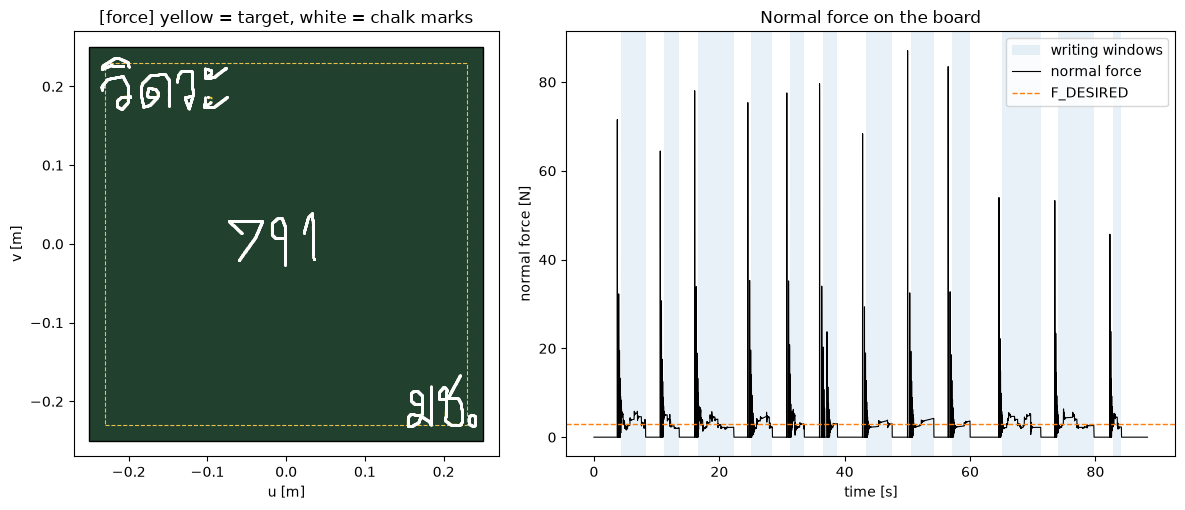

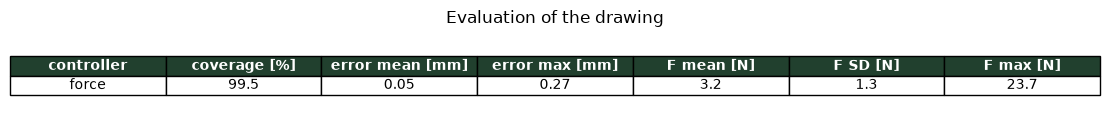

In [13]:
def point_to_segment_distance(p, a, b):
    ab = b - a
    t = np.clip(np.dot(p - a, ab) / max(np.dot(ab, ab), 1e-12), 0, 1)
    return np.linalg.norm(p - (a + t * ab))


def distance_to_strokes(p, strokes):
    return min(
        point_to_segment_distance(p, s[i], s[i + 1])
        for s in strokes
        for i in range(len(s) - 1)
    )


def evaluate(writer, strokes, coverage_tol=0.002, sample_step=0.001, verbose=True):
    X_BW = writer.X_WB_actual.inverse()
    drawn_uv = np.array([(X_BW @ p)[:2] for _, p in writer.drawn_points]).reshape(-1, 2)
    forces = np.array([
        f for t, f in writer.normal_forces
        if any(t0 <= t < t1 for t0, t1 in writer.writing_windows)
    ])
    result = dict(drawn_uv=drawn_uv, n_points=len(drawn_uv), coverage=0.0,
                  err_mean=np.nan, err_max=np.nan, f_mean=np.nan, f_std=np.nan, f_max=np.nan)
    if len(forces):
        result.update(f_mean=forces.mean(), f_std=forces.std(), f_max=forces.max())
    if len(drawn_uv):
        errors = np.array([distance_to_strokes(p, strokes) for p in drawn_uv])
        # sample the target strokes every 1 mm and check if there is a chalk mark nearby
        covered, total = 0, 0
        for s in strokes:
            if stroke_length(s) < 1e-9:  # a dot: one sample
                total += 1
                covered += np.min(np.linalg.norm(drawn_uv - s[0], axis=1)) < coverage_tol
                continue
            for i in range(len(s) - 1):
                n = max(int(np.linalg.norm(s[i + 1] - s[i]) / sample_step), 1)
                for k in range(n):
                    q = s[i] + (s[i + 1] - s[i]) * k / n
                    total += 1
                    covered += np.min(np.linalg.norm(drawn_uv - q, axis=1)) < coverage_tol
        result.update(err_mean=errors.mean(), err_max=errors.max(), coverage=100 * covered / total)
    if verbose:
        if len(drawn_uv) == 0:
            print("The chalk never touched the board.")
        else:
            print(f"Contact points: {len(drawn_uv)}")
            print(f"Tracking error: mean {result['err_mean'] * 1000:.2f} mm, max {result['err_max'] * 1000:.2f} mm")
            print(f"Coverage: {result['coverage']:.1f} %")
            print(f"Normal force while writing: mean {result['f_mean']:.2f} N, SD {result['f_std']:.2f} N, max {result['f_max']:.2f} N")
    return result


def show_table(col_labels, rows, title="", col_widths=None):
    """Show a small table as a matplotlib figure (easy to copy into slides)."""
    fig, ax = plt.subplots(figsize=(1.6 * len(col_labels), 0.45 * (len(rows) + 1) + 0.5))
    ax.axis("off")
    table = ax.table(cellText=rows, colLabels=col_labels, loc="center", cellLoc="center", colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.4)
    for (r, c), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor((0.13, 0.25, 0.18))
            cell.set_text_props(color="white", weight="bold")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_marks(ax, strokes, result, title):
    """Board view: target strokes (yellow dashed) and contact points of the chalk (white)."""
    draw_board(ax, title)
    for s in strokes:
        ax.plot(s[:, 0], s[:, 1], "--", color=(1.0, 0.8, 0.2), lw=1.2)
    if result["n_points"]:
        ax.plot(result["drawn_uv"][:, 0], result["drawn_uv"][:, 1], ".", color="white", ms=1.5)


def plot_normal_force(ax, writer, label=None, color="k"):
    t_f = np.array(writer.normal_forces)
    ax.plot(t_f[:, 0], t_f[:, 1], lw=0.8, color=color, label=label)


result = evaluate(writer, strokes)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
plot_marks(axes[0], strokes, result, f"[{CONTROL_MODE}] yellow = target, white = chalk marks")
ax = axes[1]
for k, (t0, t1) in enumerate(writer.writing_windows):
    ax.axvspan(t0, t1, color="tab:blue", alpha=0.1, lw=0, label="writing windows" if k == 0 else None)
plot_normal_force(ax, writer, label="normal force")
if CONTROL_MODE == "force":
    ax.axhline(F_DESIRED, color="tab:orange", ls="--", lw=1, label="F_DESIRED")
ax.set_xlabel("time [s]")
ax.set_ylabel("normal force [N]")
ax.set_title("Normal force on the board")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

show_table(
    ["controller", "coverage [%]", "error mean [mm]", "error max [mm]", "F mean [N]", "F SD [N]", "F max [N]"],
    [[CONTROL_MODE, f"{result['coverage']:.1f}", f"{result['err_mean'] * 1000:.2f}", f"{result['err_max'] * 1000:.2f}",
      f"{result['f_mean']:.1f}", f"{result['f_std']:.1f}", f"{result['f_max']:.1f}"]],
    title="Evaluation of the drawing",
)

## 10. Experiment: position control vs force control (Ch. 8)

**Question.** In real life the robot never knows the board pose perfectly (measurement error, a slightly bent board...).
If the board is a few millimetres away from where the robot thinks it is, how well does each controller write?

**Method.** Put the REAL board `−3, 0, +3` mm away from the board the robot believes in (+ = farther).
Run both controllers with exactly the same trajectory, using the drawing from Section 4

Each run simulates 88 s. 6 runs in total. This takes roughly 7–22 minutes, depending on the computer.
done: position board offset -3 mm
done: position board offset +0 mm
done: position board offset +3 mm
done: force    board offset -3 mm
done: force    board offset +0 mm
done: force    board offset +3 mm


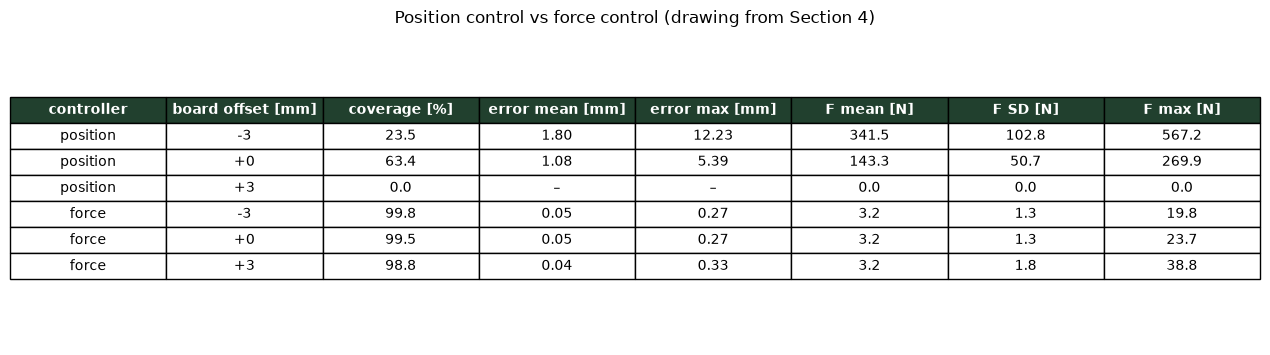

In [14]:
OFFSETS = [-0.003, 0.0, 0.003]  # m
CONTROLS = ["position", "force"]

print(f"Each run simulates {T_end:.0f} s. {len(OFFSETS) * len(CONTROLS)} runs in total. "
      f"This takes roughly {len(OFFSETS) * len(CONTROLS) * T_end * 0.8 / 60:.0f}–"
      f"{len(OFFSETS) * len(CONTROLS) * T_end * 2.5 / 60:.0f} minutes, depending on the computer.")

experiment = {}
for control in CONTROLS:
    for offset in OFFSETS:
        w, _ = build_and_run(strokes, control=control, board_offset=offset, record=False)
        r = evaluate(w, strokes, verbose=False)
        r["forces"] = np.array(w.normal_forces)
        experiment[(control, offset)] = r
        print(f"done: {control:8s} board offset {offset * 1000:+.0f} mm")


def fmt(x, scale=1.0, digits=1):
    return "–" if not np.isfinite(x) else f"{x * scale:.{digits}f}"


rows = []
for (control, offset), r in experiment.items():
    rows.append([control, f"{offset * 1000:+.0f}", f"{r['coverage']:.1f}",
                 fmt(r["err_mean"], 1000, 2), fmt(r["err_max"], 1000, 2),
                 fmt(r["f_mean"]), fmt(r["f_std"]), fmt(r["f_max"])])
show_table(
    ["controller", "board offset [mm]", "coverage [%]", "error mean [mm]", "error max [mm]",
     "F mean [N]", "F SD [N]", "F max [N]"],
    rows,
    title="Position control vs force control (drawing from Section 4)",
)

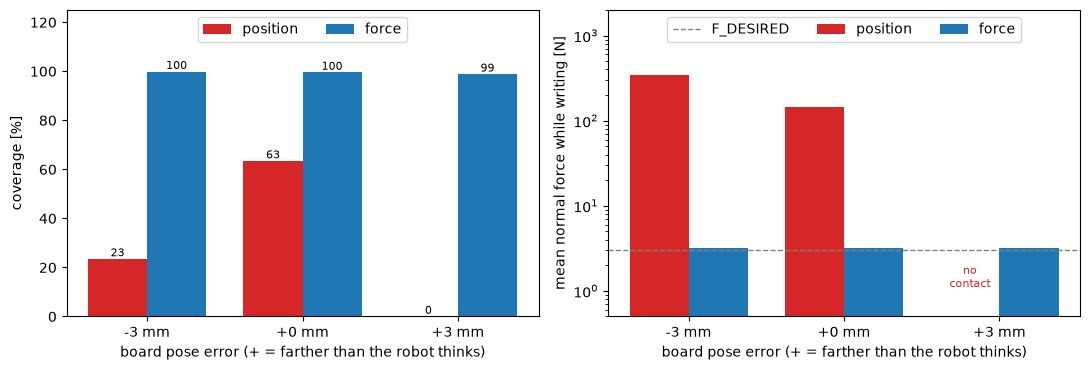

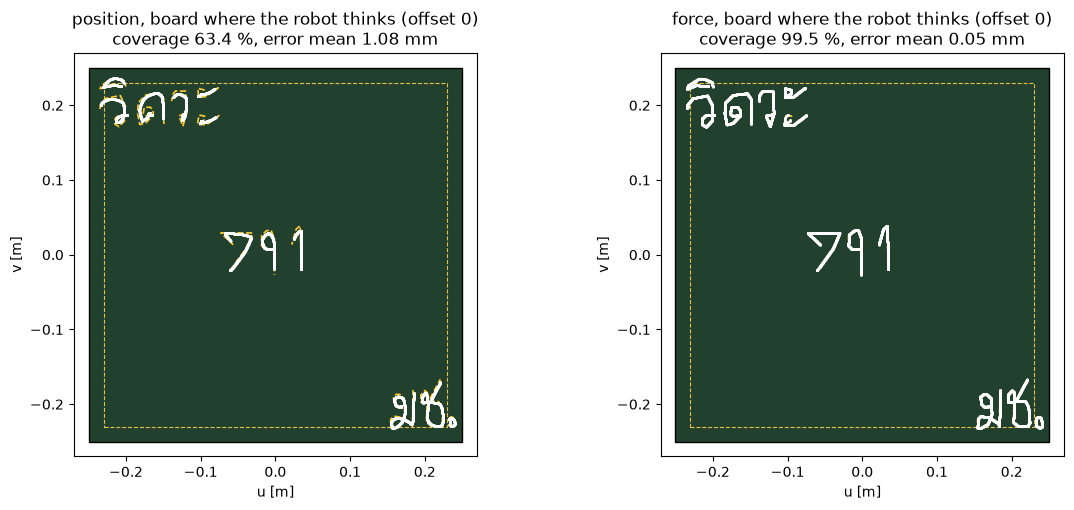

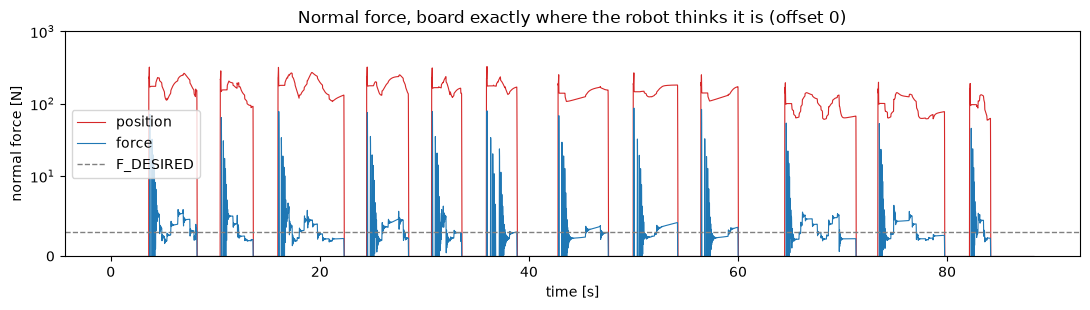

In [15]:
colors = {"position": "tab:red", "force": "tab:blue"}
x = np.arange(len(OFFSETS))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, control in enumerate(CONTROLS):
    xs = x + (k - 0.5) * width
    cov = [experiment[(control, o)]["coverage"] for o in OFFSETS]
    bars = axes[0].bar(xs, cov, width, label=control, color=colors[control])
    axes[0].bar_label(bars, fmt="%.0f", fontsize=8)
    for xi, o in zip(xs, OFFSETS):
        f_mean = experiment[(control, o)]["f_mean"]
        if experiment[(control, o)]["n_points"] == 0 or not f_mean > 0:
            axes[1].text(xi, 1.0, "no\ncontact", ha="center", va="bottom", fontsize=8, color=colors[control])
        else:
            axes[1].bar(xi, f_mean, width, color=colors[control], label=control if o == OFFSETS[0] else None)
for ax in axes:
    ax.set_xticks(x, [f"{o * 1000:+.0f} mm" for o in OFFSETS])
    ax.set_xlabel("board pose error (+ = farther than the robot thinks)")
axes[0].set_ylabel("coverage [%]")
axes[0].set_ylim(0, 125)
axes[0].legend(loc="upper center", ncol=2)
axes[1].set_ylabel("mean normal force while writing [N]")
axes[1].set_yscale("log")
axes[1].set_ylim(0.5, 2000)
axes[1].axhline(F_DESIRED, color="gray", ls="--", lw=1, label="F_DESIRED")
axes[1].legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, control in zip(axes, CONTROLS):
    r = experiment[(control, 0.0)]
    plot_marks(ax, strokes, r, f"{control}, board where the robot thinks (offset 0)\n"
                               f"coverage {r['coverage']:.1f} %, error mean {fmt(r['err_mean'], 1000, 2)} mm")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.2))
for control in CONTROLS:
    f = experiment[(control, 0.0)]["forces"]
    ax.plot(f[:, 0], f[:, 1], lw=0.8, color=colors[control], label=control)
ax.axhline(F_DESIRED, color="gray", ls="--", lw=1, label="F_DESIRED")
ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(0, 1000)
ax.set_xlabel("time [s]")
ax.set_ylabel("normal force [N]")
ax.set_title("Normal force, board exactly where the robot thinks it is (offset 0)")
ax.legend()
plt.tight_layout()
plt.show()

**How to read the results**

1. **Position control pushes very hard.** The tip is commanded only 2 mm into the board, but the iiwa joints are very stiff in position mode,
   so the force reaches about a hundred newtons or more. (A real piece of chalk would break.)
2. **High force → high friction → a less accurate line.** Friction = μ × normal force (μ = 0.3).
   The friction pulls the chalk tip behind the line, the arm bends a little, and corners become round.
3. **Position control is not robust to a board pose error.** 3 mm farther: the chalk never touches (coverage 0%).
   3 mm closer: the force goes up a lot and the line becomes worse.
4. **Force control does not care where the board is.** The results are almost the same in all three cases,
   because the normal direction controls force, not position.
   This works while the error is smaller than `APPROACH` = 5 mm, because the tip is still in position control before that height.
5. **Limitation of this force controller.** It is *open-loop* force control: it does not measure the real force and correct it.
   The real force varies about ±1 N around 3 N, because Λ is not diagonal (the force used to move along the board leaks into the normal direction).
   A next step is force feedback from the measured joint torques (`iiwa.torque_external`).
6. **Impact when the chalk first touches the board.** Both controllers show a short force peak at the first contact.
   Moving down more slowly (a larger `D_n` or a slower approach) makes it smaller, but writing takes longer.